# End-to-end CCF radial velocities — worked example

The `gamse.rv` layer turns an **extracted spectrum** (wavelength + flux) into a
**barycentric radial velocity**, by cross-correlating against a stellar line
mask. It sits on top of GAMSE's reduction (overscan → bias → trace → flat →
extraction).

**Data:** the RV standard star **HD 9407** (G6.5 V) observed on three nights with
the Xinglong 2.16 m HRS (2026-10-18, 10-26, 10-27). A standard star has a
constant true RV, so the scatter of the measured RVs *is* the instrument's RV
stability.

> How the spectra were extracted, and important caveats (double-fiber flat not
> applied; pixel/aperture offsets), are in [`REDUCTION_NOTES.md`](REDUCTION_NOTES.md).
> Short version: fine for *differential CCF RV* (measured: the flat changes the
> relative RV by only ~27 m/s), not for absolute flux until the flat is fixed.

In [1]:
import glob, os
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u

# the module this tutorial demonstrates
from gamse.rv import ccf_rv_batch, read_mask

%matplotlib inline

## 1. Inputs: extracted spectra, a line mask, and the target coordinates

Each spectrum is a small FITS file with a `WAVE / FLUX / ERR` table plus the
header keywords the RV step needs (`DATE-OBS`, `EXPTIME`, `RA`, `DEC`). The mask
is a plain two-column list (wavelength Å, line depth) restricted to 4300–6476 Å
with the 6270–6359 Å O₂ telluric band removed.

In [2]:
DATA = 'data'
files = sorted(glob.glob(os.path.join(DATA, 'hd9407_*.fits')))
mask  = read_mask(os.path.join(DATA, 'mask_GK.txt'))
coord = SkyCoord('01:34:33.0 +68:56:53', unit=(u.hourangle, u.deg))  # HD 9407

print(len(files), 'spectra,', len(mask[0]), 'mask lines')
for f in files:
    print(' ', os.path.basename(f))

7 spectra, 2666 mask lines
  hd9407_20261018_050.fits
  hd9407_20261018_051.fits
  hd9407_20261026_062.fits
  hd9407_20261026_063.fits
  hd9407_20261026_064.fits
  hd9407_20261027_043.fits
  hd9407_20261027_044.fits


## 2. One call: spectra → barycentric RVs

`ccf_rv_batch` reads each spectrum, builds the CCF against the mask, measures the
RV, and applies the barycentric correction. Xinglong `DATE-OBS` is Beijing local
time, so we pass `utc_offset_hours=8`.

- `method='gauss'` — Gaussian centroid of the mask CCF (absolute RV + BERV); best
  for sharp-lined, decent-S/N stars like this G dwarf.
- `method='chunk'` — robust chunk cross-correlation with a data-driven error;
  preferred for broad-lined / fast rotators / low S/N.

In [3]:
tab = ccf_rv_batch(files, mask, coord=coord, method='gauss', utc_offset_hours=8.0)

# report RV relative to the overall median (standard star → anomaly ~ 0)
tab['rv_ms'] -= np.median(tab['rv_ms'])

print('  file                          BJD_TDB        RV[m/s]   err[m/s]  BERV[km/s]')
for r in tab:
    print('  %-28s %.5f  %+8.1f  %7.1f  %+8.3f'
          % (r['file'], r['bjd'], r['rv_ms'], r['err_ms'], r['berv_kms']))

  file                          BJD_TDB        RV[m/s]   err[m/s]  BERV[km/s]
  hd9407_20261018_050.fits     2461332.24755    +355.1     29.9    +9.174
  hd9407_20261018_051.fits     2461332.24950    +282.3     30.5    +9.172
  hd9407_20261026_062.fits     2461340.10327      +6.6     31.1    +7.115
  hd9407_20261026_063.fits     2461340.10613     -51.5     28.5    +7.112
  hd9407_20261026_064.fits     2461340.10914      +0.0     30.0    +7.109
  hd9407_20261027_043.fits     2461341.37869     -33.3     33.3    +6.592
  hd9407_20261027_044.fits     2461341.38070     -12.7     29.9    +6.592


## 3. Per-night zero-point → the instrument's RV stability

Grouping by night shows the three-timescale picture.

In [4]:
nightkey = np.array([r['file'].split('_')[1] for r in tab])
means = {}
for nk in ['20261018', '20261026', '20261027']:
    m = nightkey == nk
    if m.any():
        means[nk] = np.mean(tab['rv_ms'][m])
        print('  %s : %+8.1f m/s  (scatter %.0f m/s, N=%d)'
              % (nk, means[nk], np.std(tab['rv_ms'][m]), m.sum()))

print('\n  adjacent nights 10-26 vs 10-27 : %+.0f m/s  (rock-stable)'
      % (means['20261027'] - means['20261026']))
print('  ~8-day drift   10-18 vs 10-27 : %+.0f m/s  (tie with standard stars)'
      % (means['20261027'] - means['20261018']))

  20261018 :   +318.7 m/s  (scatter 36 m/s, N=2)
  20261026 :    -15.0 m/s  (scatter 26 m/s, N=3)
  20261027 :    -23.0 m/s  (scatter 10 m/s, N=2)

  adjacent nights 10-26 vs 10-27 : -8 m/s  (rock-stable)
  ~8-day drift   10-18 vs 10-27 : -342 m/s  (tie with standard stars)


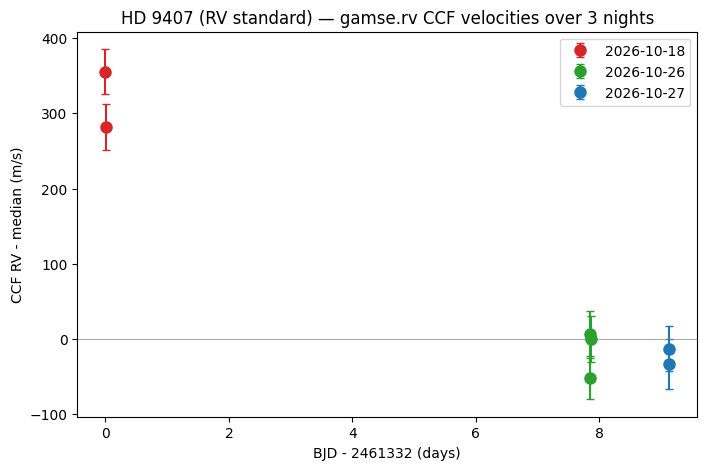

In [5]:
colors = {'20261018': 'tab:red', '20261026': 'tab:green', '20261027': 'tab:blue'}
labels = {'20261018': '2026-10-18', '20261026': '2026-10-26', '20261027': '2026-10-27'}
fig, ax = plt.subplots(figsize=(8, 5))
for nk in colors:
    m = nightkey == nk
    if not m.any():
        continue
    ax.errorbar(tab['bjd'][m] - tab['bjd'].min(), tab['rv_ms'][m], tab['err_ms'][m],
                fmt='o', ms=8, capsize=3, color=colors[nk], label=labels[nk])
ax.axhline(0, color='gray', lw=0.5)
ax.set_xlabel('BJD - %.0f (days)' % tab['bjd'].min())
ax.set_ylabel('CCF RV - median (m/s)')
ax.set_title('HD 9407 (RV standard) — gamse.rv CCF velocities over 3 nights')
ax.legend()
plt.show()

**Takeaway:** adjacent nights repeat to ~m/s; there is a few-hundred-m/s common
zero-point drift over ~8 days that must be removed with standard stars before
combining multi-night RVs. The module stops at RV — orbit / Rossiter-McLaughlin
modelling is left to downstream tools.